# 09 — Candlestick pattern recognition

*Extension: min / max price · code: `src/sp500/patterns.py`*

Detects 13 classic candlestick patterns with vectorized rules that only use candles up to day *t* (so they can be model features), then measures what the S&P 500 did after each one.

← previous: [`08_holdout.ipynb`](08_holdout.ipynb) · next: [`10_candle_resampling.ipynb`](10_candle_resampling.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
from sp500.config import DATA_PROCESSED
from sp500.patterns import PATTERNS, detect_patterns, pattern_score, pattern_stats
from sp500.range_data import forward_extremes
from sp500.plots import plot_candles, mark_patterns

daily = pd.read_parquet(DATA_PROCESSED / "sp500_daily.parquet")
ohlc = daily[["gspc_open", "gspc_high", "gspc_low", "gspc_close"]].loc["1962-07":].dropna()
ohlc.columns = ["open", "high", "low", "close"]
pd.DataFrame([(k, d, t) for k, (d, t) in PATTERNS.items()], columns=["pattern", "signal", "rule"])

,pattern,signal,rule
0,doji,neutral,Body < 10% of the range: indecision
1,hammer,bullish,"Small body on top, long lower shadow, after a ..."
2,shooting_star,bearish,"Small body at the bottom, long upper shadow, a..."
3,bullish_engulfing,bullish,Up candle whose body engulfs the previous down...
4,bearish_engulfing,bearish,Down candle whose body engulfs the previous up...
5,morning_star,bullish,"Down candle, small candle, strong up candle"
6,evening_star,bearish,"Up candle, small candle, strong down candle"
7,three_white_soldiers,bullish,"Three up candles, each closing higher"
8,three_black_crows,bearish,"Three down candles, each closing lower"
9,inside_bar,neutral,Range inside the previous range: volatility sq...


## 1. Detect

Rules use the candle body, shadows and range, the 20-candle average body, and a 5-candle trend (hammer / shooting star need a prior fall / rise).

In [3]:
flags = detect_patterns(ohlc)
counts = flags.sum().astype(int).rename("days").to_frame()
counts["share of days"] = counts["days"] / flags.notna().all(axis=1).sum()
counts.style.format({"share of days": "{:.1%}"})

,days,share of days
doji,2009,12.4%
hammer,515,3.2%
shooting_star,451,2.8%
bullish_engulfing,1349,8.4%
bearish_engulfing,1236,7.7%
morning_star,317,2.0%
evening_star,301,1.9%
three_white_soldiers,1596,9.9%
three_black_crows,1201,7.4%
inside_bar,1538,9.5%


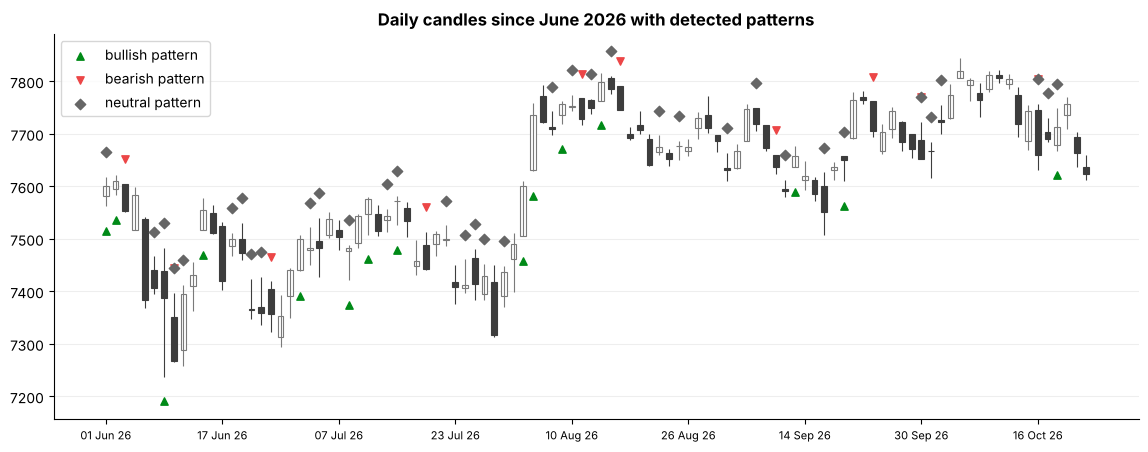

[(datetime.date(2026, 10, 16), 'bearish_engulfing'),
 (datetime.date(2026, 10, 16), 'outside_bar'),
 (datetime.date(2026, 10, 19), 'inside_bar'),
 (datetime.date(2026, 10, 20), 'bullish_engulfing'),
 (datetime.date(2026, 10, 20), 'morning_star'),
 (datetime.date(2026, 10, 20), 'outside_bar')]

In [4]:
recent = ohlc.loc["2026-06":]
fig, ax = plt.subplots(figsize=(14, 5))
plot_candles(ax, recent)
mark_patterns(ax, recent, flags.loc[recent.index], PATTERNS)
ax.set_title("Daily candles since June 2026 with detected patterns"); ax.legend(loc="upper left")
plt.show()
last = flags.loc[recent.index].tail(10)
[(d.date(), k) for d in last.index for k in PATTERNS if last.loc[d, k] == 1]

## 2. Is the detector causal?

Flags computed on data cut at a past date must equal the flags of the full history.

In [5]:
cut = "2015-06-17"
assert flags.loc[:cut].equals(detect_patterns(ohlc.loc[:cut])), "look-ahead!"
print("OK: identical flags on truncated data")

OK: identical flags on truncated data


## 3. What happened next?

For every pattern: share of up weeks / months, the average return, and the average **maximum rise** (highest high) and **maximum fall** (lowest low) over the next *h* days, compared with *all days*.

In [6]:
stats = []
for h in (5, 21):
    fx = forward_extremes(daily.loc[ohlc.index], h)
    s = pattern_stats(flags, fx[f"up_{h}"], fx[f"down_{h}"], fx[f"ret_{h}"]).assign(h=h)
    s["range"] = s["avg_max_up"] - s["avg_max_down"]
    stats.append(s)
stats = pd.concat(stats)
fmt = {"hit_rate_up": "{:.1%}", "avg_ret": "{:+.2%}", "avg_max_up": "{:+.2%}", "avg_max_down": "{:+.2%}", "range": "{:.2%}"}
stats[stats.h == 5].drop(columns="h").style.format(fmt)

,pattern,direction,count,hit_rate_up,avg_ret,avg_max_up,avg_max_down,range
0,all days,,16143,56.6%,+0.15%,+1.61%,-1.63%,3.25%
1,doji,neutral,2009,55.4%,+0.15%,+1.59%,-1.54%,3.13%
2,hammer,bullish,515,56.3%,+0.15%,+1.69%,-1.80%,3.49%
3,shooting_star,bearish,451,59.0%,+0.29%,+1.61%,-1.46%,3.07%
4,bullish_engulfing,bullish,1348,57.6%,+0.19%,+1.63%,-1.46%,3.09%
5,bearish_engulfing,bearish,1236,52.6%,+0.05%,+1.54%,-1.79%,3.32%
6,morning_star,bullish,316,55.4%,+0.05%,+1.62%,-1.78%,3.40%
7,evening_star,bearish,301,57.5%,+0.01%,+1.60%,-1.86%,3.46%
8,three_white_soldiers,bullish,1596,59.5%,+0.14%,+1.44%,-1.37%,2.81%
9,three_black_crows,bearish,1201,56.1%,+0.31%,+1.95%,-1.91%,3.87%


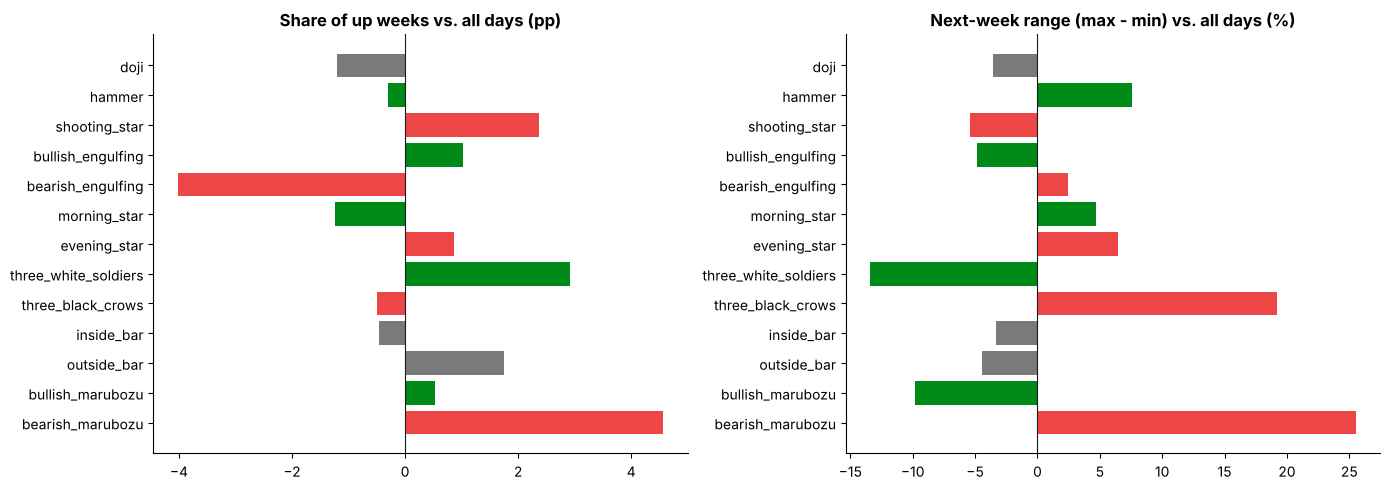

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
s = stats[stats.h == 5].set_index("pattern")
base = s.loc["all days"]
s = s.drop("all days")
col = s["direction"].map({"bullish": "#008a17", "bearish": "#ec4647", "neutral": "#7a7a7a"})
axes[0].barh(s.index, (s["hit_rate_up"] - base["hit_rate_up"]) * 100, color=col)
axes[0].set_title("Share of up weeks vs. all days (pp)")
axes[1].barh(s.index, (s["range"] / base["range"] - 1) * 100, color=col)
axes[1].set_title("Next-week range (max - min) vs. all days (%)")
for ax in axes:
    ax.axvline(0, color="#191919", lw=0.8); ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Result.** On the S&P 500, single candlestick patterns barely change the *direction* of the next week (53–61% up weeks vs. 57% on all days). They say more about the *size* of the coming move: strong bearish candles (three black crows, bearish marubozu) come before ranges ~20–25% wider than usual, three white soldiers before narrower ones. So patterns are used as **features for the range models**, not as stand-alone trading signals.